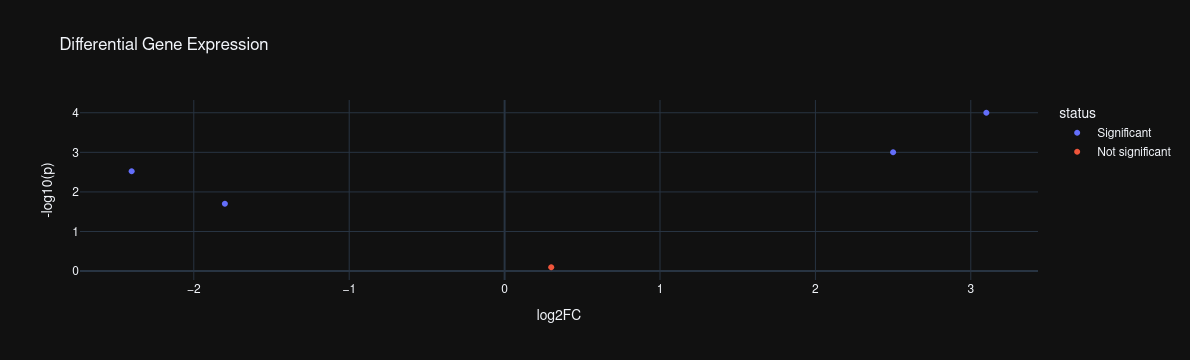

In [1]:
import plotly.express as px
import numpy as np
import pandas as pd

df = pd.DataFrame({
    "gene": ["TP53", "MYC", "BRCA1", "EGFR", "CDK1"],
    "log2FC": [2.5, -1.8, 0.3, 3.1, -2.4], 
    "pvalue": [0.001, 0.02, 0.8, 0.0001, 0.003],
})

df["-log10(p)"] = -np.log10(df["pvalue"])

df["status"] = np.where(
    (df["pvalue"] < 0.05) & (abs(df["log2FC"]) > 1),
    "Significant",
    "Not significant"
)

fig = px.scatter(
    df,
    x="log2FC",
    y="-log10(p)",
    color="status",
    hover_name="gene",
    hover_data=["pvalue"],
    title="Differential Gene Expression",
    template="plotly_dark",
)

fig.show()